# Entrenamiento y ajuste de los modelos base

En este notebook entrenamos y ajustamos los cinco modelos base con la misma partición agrupada (group-aware), el mismo preprocesamiento y la misma métrica, el PR-AUC. Para cada modelo miramos una curva de validación, buscamos la mejor combinación de hiperparámetros y nos quedamos con el estimador final. La comparación entre los seis modelos, la evaluación en test y la decisión de negocio las dejamos para 4_evaluation.

Una aclaración pa que no haya confusión, los valores de este notebook salen de la validación cruzada que usamos para ajustar, no de la CV repetida 5×5 de la evaluación final, así que el número de un mismo modelo puede cambiar de un notebook a otro.

# Modelo 1 — Regresión logística

c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== 10. MODELO 1: REGRESIÓN LOGÍSTICA ===

Scores de Validación Cruzada (Curva de Validación):
  C =    0.001 -> PR-AUC Validación = 0.6721 ± 0.0573 (Desviación entre pliegues)
  C =    0.010 -> PR-AUC Validación = 0.6896 ± 0.0498 (Desviación entre pliegues)
  C =    0.100 -> PR-AUC Validación = 0.6879 ± 0.0404 (Desviación entre pliegues)
  C =    1.000 -> PR-AUC Validación = 0.6852 ± 0.0324 (Desviación entre pliegues)
  C =   10.000 -> PR-AUC Validación = 0.6822 ± 0.0277 (Desviación entre pliegues)
  C =  100.000 -> PR-AUC Validación = 0.6816 ± 0.0273 (Desviación entre pliegues)


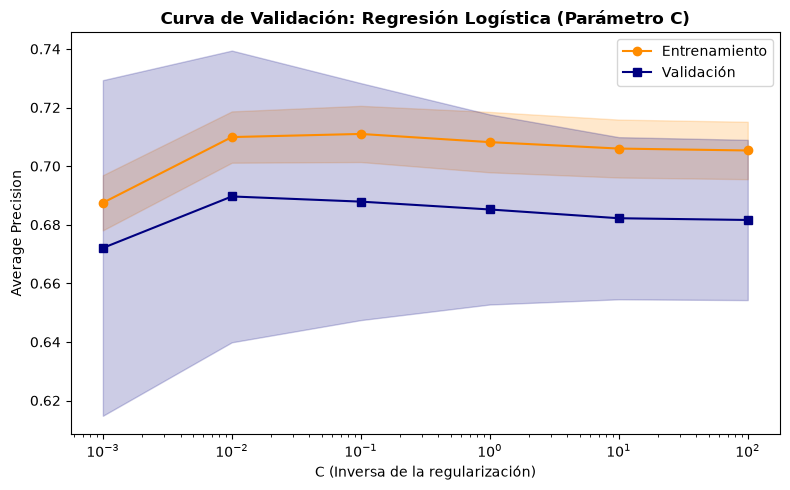

Optimizando modelo...
Mejores hiperparámetros: {'clf__C': 0.01, 'clf__solver': 'lbfgs'}
PR-AUC de validación cruzada: 0.6896 ± 0.0498 (Desviación entre pliegues)
PR-AUC de entrenamiento del mejor estimador: 0.7099


In [1]:
import sys
from pathlib import Path

raiz = Path.cwd().resolve()
candidatas_raiz = [raiz, *raiz.parents]

# En Colab el repositorio puede estar en /content/<nombre-repo>, no en el CWD.
for base in (Path("/content"), Path("/workspace"), Path("/mnt/data")):
    if base.is_dir():
        candidatas_raiz.extend(hijo for hijo in base.iterdir() if hijo.is_dir())

for candidato in candidatas_raiz:
    if (candidato / "src").is_dir() and (candidato / "notebooks").is_dir():
        sys.path.insert(0, str(candidato))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import time

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import validation_curve, learning_curve, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from src.comun import (
    SEED,
    guardar,
    guardar_estado,
    cargar_estado,
    configurar_columnas,
    construir_preprocesador,
    resumen_grid,
)

globals().update(cargar_estado("1_eda"))
globals().update(cargar_estado("2_preprocessing"))
configurar_columnas(all_num_features, all_cat_features, cols_na)

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import validation_curve, StratifiedKFold, GridSearchCV
import time


print("=== 10. MODELO 1: REGRESIÓN LOGÍSTICA ===")

cv_tuning = CV_TUNING

metrica = "average_precision"

logreg_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", LogisticRegression(
        class_weight="balanced",
        random_state=SEED,
        max_iter=2000,
        solver="lbfgs"
    ))
])

rango_C = np.logspace(-3, 2, 6)

train_scores, test_scores = validation_curve(
    logreg_base,
    X_train,
    y_train,
    param_name="clf__C",
    param_range=rango_C,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

print("\nScores de Validación Cruzada (Curva de Validación):")
for c, score, std in zip(rango_C, test_mean, test_std):
    print(f"  C = {c:8.3f} -> PR-AUC Validación = {score:.4f} \u00b1 {std:.4f} (Desviación entre pliegues)")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    rango_C, train_mean,
    label="Entrenamiento",
    color="darkorange",
    marker="o"
)
ax.fill_between(
    rango_C,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2,
    color="darkorange"
)

ax.plot(
    rango_C, test_mean,
    label="Validaci\u00f3n",
    color="navy",
    marker="s"
)
ax.fill_between(
    rango_C,
    test_mean - test_std,
    test_mean + test_std,
    alpha=0.2,
    color="navy"
)

ax.set_title(
    "Curva de Validaci\u00f3n: Regresi\u00f3n Log\u00edstica (Par\u00e1metro C)",
    fontweight="bold"
)
ax.set_xscale("log")
ax.set_xlabel("C (Inversa de la regularizaci\u00f3n)")
ax.set_ylabel("Average Precision")
ax.legend()

plt.tight_layout()
plt.show()

print("Optimizando modelo...")

malla_lr = {
    "clf__C": [0.01, 0.1, 1.0, 10.0],
    "clf__solver": ["lbfgs", "liblinear"]
}

grid_lr = GridSearchCV(
    logreg_base,
    malla_lr,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1,
    return_train_score=True
)

grid_lr.fit(X_train, y_train)

print(f"Mejores hiperpar\u00e1metros: {grid_lr.best_params_}")

best_idx = grid_lr.best_index_
val_mean = grid_lr.cv_results_['mean_test_score'][best_idx]
val_std = grid_lr.cv_results_['std_test_score'][best_idx]
print(f"PR-AUC de validaci\u00f3n cruzada: {val_mean:.4f} \u00b1 {val_std:.4f} (Desviaci\u00f3n entre pliegues)")

mean_train_score = grid_lr.cv_results_['mean_train_score'][best_idx]
print(f"PR-AUC de entrenamiento del mejor estimador: {mean_train_score:.4f}")

modelo_lr_final = grid_lr.best_estimator_

En la regresión logística la curva de validación se aplana desde C = 0,01, y el mejor punto fue justo ahí (C = 0,01, solver lbfgs), con un PR-AUC de 0,690 en validación y 0,710 en entrenamiento. Es el modelo más flojo de los cinco, pero lo dejamos como línea base porque es el más fácil de interpretar.

# Modelo 2 — K-vecinos más cercanos (KNN)

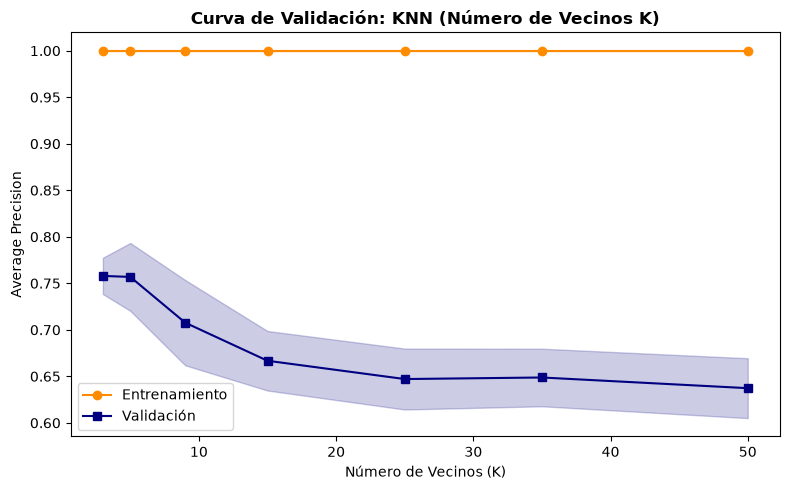

Optimizando modelo...
Mejores hiperparámetros: {'clf__n_neighbors': 5, 'clf__p': 1, 'clf__weights': 'distance'}
PR-AUC de validación cruzada: 0.7641


In [2]:
from sklearn.neighbors import KNeighborsClassifier

cv_tuning = CV_TUNING

metrica = "average_precision"

knn_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", KNeighborsClassifier(
        weights="distance",
        p=2
    ))
])

rango_K = [3, 5, 9, 15, 25, 35, 50]

train_scores, test_scores = validation_curve(
    knn_base,
    X_train,
    y_train,
    param_name="clf__n_neighbors",
    param_range=rango_K,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    rango_K, train_mean,
    label="Entrenamiento",
    color="darkorange",
    marker="o"
)
ax.fill_between(
    rango_K,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2,
    color="darkorange"
)

ax.plot(
    rango_K, test_mean,
    label="Validación",
    color="navy",
    marker="s"
)
ax.fill_between(
    rango_K,
    test_mean - test_std,
    test_mean + test_std,
    alpha=0.2,
    color="navy"
)

ax.set_title(
    "Curva de Validación: KNN (Número de Vecinos K)",
    fontweight="bold"
)
ax.set_xlabel("Número de Vecinos (K)")
ax.set_ylabel("Average Precision")
ax.legend()

plt.tight_layout()
plt.show()

# 3. Búsqueda de hiperparámetros
print("Optimizando modelo...")

malla_knn = {
    "clf__n_neighbors": [3, 5, 9, 15, 25, 35, 50],
    "clf__weights": ["uniform", "distance"],
    "clf__p": [1, 2]
}

grid_knn = GridSearchCV(
    knn_base,
    malla_knn,
    cv=cv_tuning,
    scoring=metrica,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print(f"Mejores hiperparámetros: {grid_knn.best_params_}")
print(f"PR-AUC de validación cruzada: {grid_knn.best_score_:.4f}")

modelo_knn_final = grid_knn.best_estimator_

En KNN la búsqueda se quedó con k = 5, pesos por distancia y distancia Manhattan, con un PR-AUC de 0,764 en validación. Los k pequeños resultaron competitivos. Más abajo vemos que el 1,000 de entrenamiento se debe a que cada punto es su propio vecino y no a una fuga entre entrenamiento y validación.

# Funciones auxiliares para curvas de validación

In [4]:
from sklearn.model_selection import validation_curve, learning_curve, GridSearchCV, StratifiedKFold
from sklearn.base import clone
import time

cv_tuning = CV_TUNING
metrica = "average_precision"


def curva_validacion(estimador, param_name, rango, titulo, xlabel, ax, log_x=False, etiquetas=None):
    tr, va = validation_curve(
        estimador, X_train, y_train, param_name=param_name, param_range=rango,
        cv=cv_tuning, scoring=metrica, n_jobs=-1
    )
    tr_m, tr_s, va_m, va_s = tr.mean(1), tr.std(1), va.mean(1), va.std(1)
    etiquetas = etiquetas if etiquetas is not None else [str(r) for r in rango]
    categorico = any(r is None or isinstance(r, (str, tuple)) for r in rango)
    x = np.arange(len(rango)) if categorico else np.asarray(rango, dtype=float)

    ax.plot(x, tr_m, "o-", color="darkorange", label="Entrenamiento")
    ax.fill_between(x, tr_m - tr_s, tr_m + tr_s, alpha=0.2, color="darkorange")
    ax.plot(x, va_m, "s-", color="navy", label="Validación")
    ax.fill_between(x, va_m - va_s, va_m + va_s, alpha=0.2, color="navy")

    mejor = int(np.argmax(va_m))
    ax.axvline(x[mejor], ls="--", color="green", alpha=0.8, label=f"Máx. validación: {etiquetas[mejor]}")
    if categorico:
        ax.set_xticks(x)
        ax.set_xticklabels(etiquetas, rotation=30, ha="right")
    if log_x:
        ax.set_xscale("log")
    ax.set_title(titulo, fontweight="bold", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Average Precision (PR-AUC)")
    ax.legend(fontsize=8)
    return pd.DataFrame({"valor": etiquetas, "train": tr_m, "val": va_m, "val_std": va_s})


def mapa_calor_grid(grid, p_fila, p_col, titulo, ax, ylabel, xlabel):
    pg = grid.param_grid if isinstance(grid.param_grid, dict) else grid.param_grid[0]
    filas, cols = list(pg[p_fila]), list(pg[p_col])
    M = np.full((len(filas), len(cols)), np.nan)
    for p, s in zip(grid.cv_results_["params"], grid.cv_results_["mean_test_score"]):
        i, j = filas.index(p[p_fila]), cols.index(p[p_col])
        M[i, j] = s if np.isnan(M[i, j]) else max(M[i, j], s)

    sns.heatmap(M, annot=True, fmt=".3f", cmap="viridis", ax=ax,
                xticklabels=[str(c) for c in cols], yticklabels=[str(f) for f in filas],
                cbar_kws={"label": "PR-AUC de validación (CV)"})
    bi, bj = filas.index(grid.best_params_[p_fila]), cols.index(grid.best_params_[p_col])
    ax.add_patch(plt.Rectangle((bj, bi), 1, 1, fill=False, edgecolor="red", lw=3))
    ax.set_title(titulo, fontweight="bold", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)




=== REVISIÓN DEL MODELO 2 (KNN): ¿por qué el score de entrenamiento es siempre 1.0? ===
Puntos de entrenamiento cuyo vecino más cercano está a distancia 0 (él mismo): 100.0%
  k=5, weights='distance': PR-AUC evaluado sobre los propios datos de entrenamiento = 1.0000
  k=5, weights='uniform': PR-AUC evaluado sobre los propios datos de entrenamiento = 0.9500


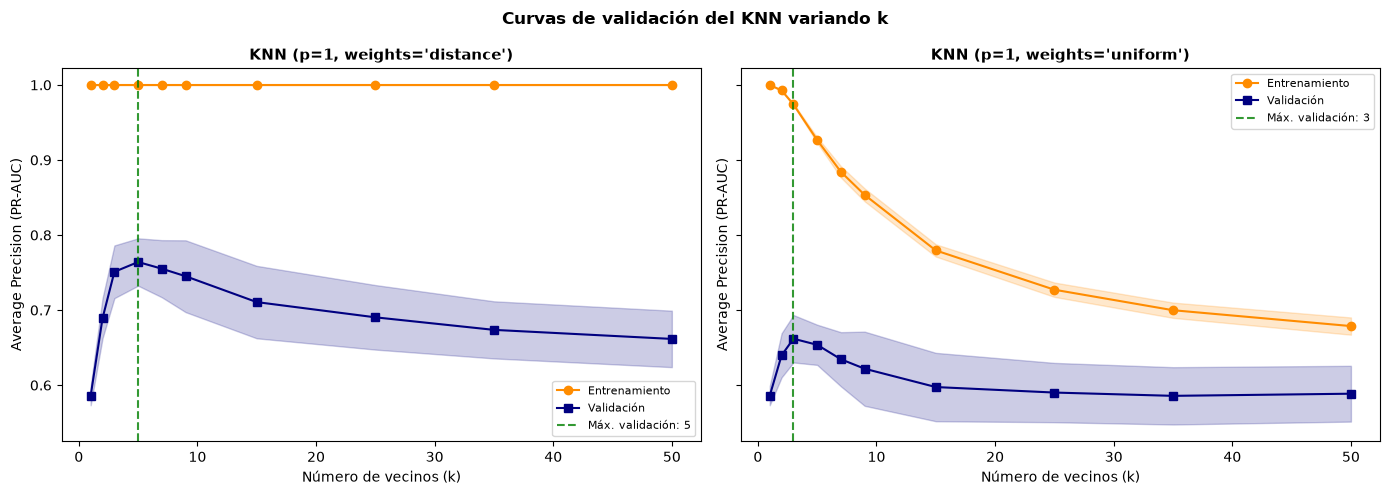

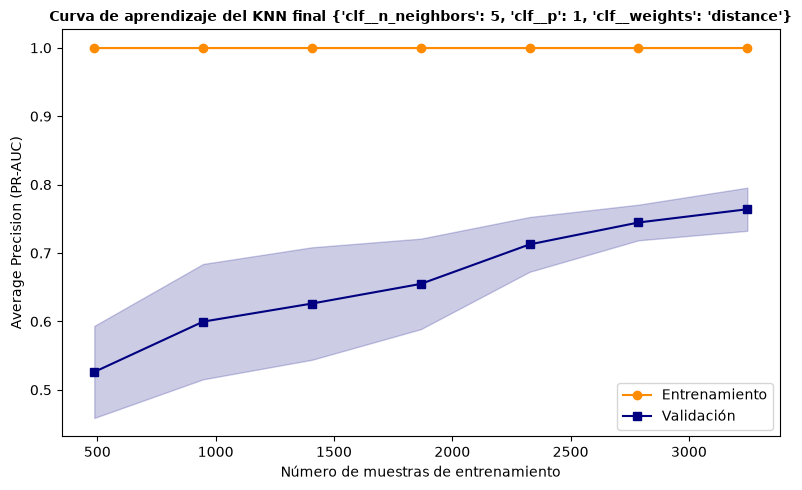

Malla ampliada (incluye k pequeños)...

KNN con malla ampliada
  Mejores hiperparametros: {'clf__n_neighbors': 5, 'clf__p': 1, 'clf__weights': 'distance'}  PR-AUC validacion CV: 0.7641 +/- 0.0316 | entrenamiento: 1.0000 | brecha train-val: 0.2359


,params,mean_train_score,mean_test_score,std_test_score
13,"{'clf__n_neighbors': 5, 'clf__p': 1, 'clf__wei...",1.0,0.7641,0.0316
11,"{'clf__n_neighbors': 3, 'clf__p': 2, 'clf__wei...",1.0,0.7580,0.0195
15,"{'clf__n_neighbors': 5, 'clf__p': 2, 'clf__wei...",1.0,0.7569,0.0365
17,"{'clf__n_neighbors': 7, 'clf__p': 1, 'clf__wei...",1.0,0.7551,0.0381
9,"{'clf__n_neighbors': 3, 'clf__p': 1, 'clf__wei...",1.0,0.7510,0.0351



Referencia - malla original: {'clf__n_neighbors': 5, 'clf__p': 1, 'clf__weights': 'distance'} -> PR-AUC CV = 0.7641

Distancia (Manhattan, espacio preprocesado) del vecino más cercano en train para cada fila de validación:
count    811.000
mean       4.846
std        2.224
min        0.664
5%         1.275
25%        3.275
50%        4.959
75%        5.971
max       14.505
Filas de validación con un vecino idéntico en train (distancia = 0): 0.0%


In [5]:
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors

print("=== REVISIÓN DEL MODELO 2 (KNN): ¿por qué el score de entrenamiento es siempre 1.0? ===")

def pipeline_knn(**params):
    return Pipeline([
        ("prep", construir_preprocesador(estrategia_final)),
        ("clf", KNeighborsClassifier(**params))
    ])

# ---------------------------------------------------------------------------------
# 1) Diagnóstico: con weights="distance", cada punto de entrenamiento es su propio vecino
# ---------------------------------------------------------------------------------
prep_diag = construir_preprocesador(estrategia_final)
Xtr_p = prep_diag.fit_transform(X_train)

knn_diag = KNeighborsClassifier(n_neighbors=5, weights="distance", p=1).fit(Xtr_p, y_train)
dist_self, _ = knn_diag.kneighbors(Xtr_p, n_neighbors=1)
print(f"Puntos de entrenamiento cuyo vecino más cercano está a distancia 0 (él mismo): "
      f"{(dist_self[:, 0] == 0).mean():.1%}")

from sklearn.metrics import average_precision_score
for w in ["distance", "uniform"]:
    m = KNeighborsClassifier(n_neighbors=5, weights=w, p=1).fit(Xtr_p, y_train)
    ap = average_precision_score(y_train, m.predict_proba(Xtr_p)[:, 1])
    print(f"  k=5, weights='{w}': PR-AUC evaluado sobre los propios datos de entrenamiento = {ap:.4f}")

# ---------------------------------------------------------------------------------
# 2) Curvas de validación variando k: weights="distance" vs. weights="uniform" (incluye k=1 y k=2)
# ---------------------------------------------------------------------------------
rango_K = [1, 2, 3, 5, 7, 9, 15, 25, 35, 50]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
tablas_k = {}
for ax, w in zip(axes, ["distance", "uniform"]):
    tablas_k[w] = curva_validacion(
        pipeline_knn(weights=w, p=1), "clf__n_neighbors", rango_K,
        f"KNN (p=1, weights='{w}')", "Número de vecinos (k)", ax
    )
fig.suptitle("Curvas de validación del KNN variando k", fontweight="bold")
plt.tight_layout()
guardar(fig, "11_knn_curvas_validacion_k")
plt.show()

# ---------------------------------------------------------------------------------
# 3) Curva de aprendizaje de la configuración elegida (modelo_knn_final)
# ---------------------------------------------------------------------------------
tamanos, tr_lc, va_lc = learning_curve(
    clone(modelo_knn_final), X_train, y_train, train_sizes=np.linspace(0.15, 1.0, 7),
    cv=cv_tuning, scoring=metrica, n_jobs=-1
)
fig, ax = plt.subplots(figsize=(8, 5))
for nombre, sc, color, mk in [("Entrenamiento", tr_lc, "darkorange", "o"), ("Validación", va_lc, "navy", "s")]:
    ax.plot(tamanos, sc.mean(1), marker=mk, color=color, label=nombre)
    ax.fill_between(tamanos, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=0.2, color=color)
ax.set_title(f"Curva de aprendizaje del KNN final {grid_knn.best_params_}", fontweight="bold", fontsize=10)
ax.set_xlabel("Número de muestras de entrenamiento")
ax.set_ylabel("Average Precision (PR-AUC)")
ax.legend()
plt.tight_layout()
guardar(fig, "11_knn_curva_aprendizaje")
plt.show()

# ---------------------------------------------------------------------------------
# 4) ¿El óptimo estaba en el borde de la malla original (k=3)? Malla ampliada con k=1..
# ---------------------------------------------------------------------------------
print("Malla ampliada (incluye k pequeños)...")
malla_knn_ext = {
    "clf__n_neighbors": [1, 2, 3, 5, 7, 9, 15, 25],
    "clf__weights": ["uniform", "distance"],
    "clf__p": [1, 2],
}
grid_knn_ext = GridSearchCV(
    pipeline_knn(), malla_knn_ext, cv=cv_tuning, scoring=metrica, n_jobs=-1, return_train_score=True
)
grid_knn_ext.fit(X_train, y_train)
resumen_grid("KNN con malla ampliada", grid_knn_ext)
print(f"\nReferencia - malla original: {grid_knn.best_params_} -> PR-AUC CV = {grid_knn.best_score_:.4f}")

# ---------------------------------------------------------------------------------
# 5) Chequeo de vecinos casi idénticos entre pliegues (explica por qué k pequeño gana)
# ---------------------------------------------------------------------------------
idx_tr, idx_va = CV_TUNING[0]
assert set(grupos_train[idx_tr]).isdisjoint(grupos_train[idx_va]), "Fuga de grupos dentro del pliegue"

prep_fold = construir_preprocesador(estrategia_final).fit(X_train.iloc[idx_tr])
nn_fold = NearestNeighbors(n_neighbors=1, metric="manhattan").fit(prep_fold.transform(X_train.iloc[idx_tr]))
d_va, _ = nn_fold.kneighbors(prep_fold.transform(X_train.iloc[idx_va]))
d_va = d_va[:, 0]
print("\nDistancia (Manhattan, espacio preprocesado) del vecino más cercano en train para cada fila de validación:")
print(pd.Series(d_va).describe(percentiles=[0.05, 0.25, 0.5, 0.75]).round(3).to_string())
print(f"Filas de validación con un vecino idéntico en train (distancia = 0): {(d_va <= 1e-9).mean():.1%}")

Revisamos por qué KNN saca 1,000 en entrenamiento: el 100 % de los puntos tiene como vecino más cercano a sí mismo, a distancia 0. En validación pasa lo contrario, ninguna fila tiene un vecino idéntico en entrenamiento, así que no hay fuga. Con la malla ampliada, que incluye k pequeños, el mejor sigue siendo k = 5 con 0,764, pero la brecha con entrenamiento sigue alta (0,236), por eso no lo consideramos como modelo final.

# Modelo 3 — Random Forest


=== MODELO 3: RANDOM FOREST (ensamble de árboles de decisión) ===


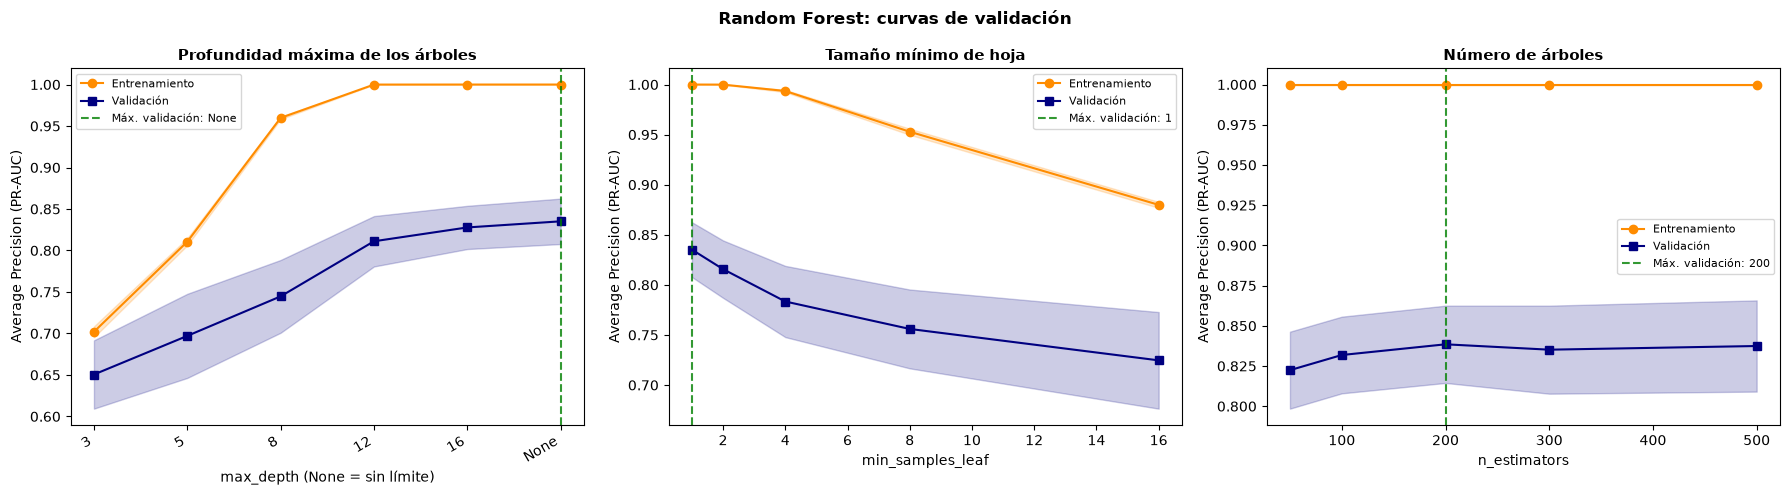

Optimizando modelo...

Random Forest
  Mejores hiperparametros: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}  PR-AUC validacion CV: 0.8352 +/- 0.0274 | entrenamiento: 1.0000 | brecha train-val: 0.1648


,params,mean_train_score,mean_test_score,std_test_score
18,"{'clf__max_depth': None, 'clf__max_features': ...",1.0000,0.8352,0.0274
21,"{'clf__max_depth': None, 'clf__max_features': ...",1.0000,0.8270,0.0299
19,"{'clf__max_depth': None, 'clf__max_features': ...",0.9999,0.8157,0.0287
15,"{'clf__max_depth': 12, 'clf__max_features': 0....",1.0000,0.8128,0.0282
22,"{'clf__max_depth': None, 'clf__max_features': ...",0.9999,0.8128,0.0298


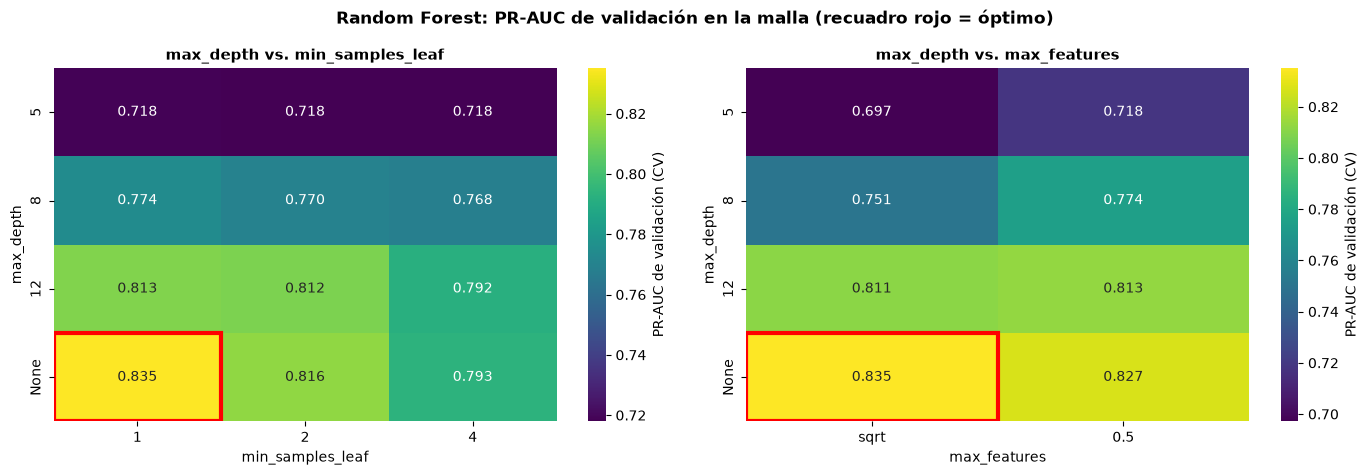

Tiempo total del Modelo 3: 0.8 min


In [6]:
from sklearn.ensemble import RandomForestClassifier

print("=== MODELO 3: RANDOM FOREST (ensamble de árboles de decisión) ===")

rf_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=1
    ))
])

inicio = time.time()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

rango_depth = [3, 5, 8, 12, 16, None]
curva_validacion(rf_base, "clf__max_depth", rango_depth, "Profundidad máxima de los árboles",
                 "max_depth (None = sin límite)", axes[0], etiquetas=["3", "5", "8", "12", "16", "None"])

rango_leaf = [1, 2, 4, 8, 16]
curva_validacion(rf_base, "clf__min_samples_leaf", rango_leaf, "Tamaño mínimo de hoja",
                 "min_samples_leaf", axes[1])

rango_trees = [50, 100, 200, 300, 500]
curva_validacion(rf_base, "clf__n_estimators", rango_trees, "Número de árboles",
                 "n_estimators", axes[2])

fig.suptitle("Random Forest: curvas de validación", fontweight="bold")
plt.tight_layout()
guardar(fig, "12_rf_curvas_validacion")
plt.show()

print("Optimizando modelo...")
malla_rf = {
    "clf__max_depth": [5, 8, 12, None],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", 0.5],
}

grid_rf = GridSearchCV(
    rf_base, malla_rf, cv=cv_tuning, scoring=metrica, n_jobs=-1, return_train_score=True
)
grid_rf.fit(X_train, y_train)
resumen_grid("Random Forest", grid_rf)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
mapa_calor_grid(grid_rf, "clf__max_depth", "clf__min_samples_leaf",
                "max_depth vs. min_samples_leaf", axes[0], "max_depth", "min_samples_leaf")
mapa_calor_grid(grid_rf, "clf__max_depth", "clf__max_features",
                "max_depth vs. max_features", axes[1], "max_depth", "max_features")
fig.suptitle("Random Forest: PR-AUC de validación en la malla (recuadro rojo = óptimo)", fontweight="bold")
plt.tight_layout()
guardar(fig, "12_rf_mapas_calor")
plt.show()

modelo_rf_final = grid_rf.best_estimator_
print(f"Tiempo total del Modelo 3: {(time.time() - inicio) / 60:.1f} min")

El mejor Random Forest usó árboles sin límite de profundidad y hojas de una sola muestra, y llegó a un PR-AUC de 0,835 en validación, con una brecha de 0,165 frente a entrenamiento. En la tabla de resultados casi todas las mejores combinaciones tienen profundidad ilimitada. Es competitivo, pero la SVM lo supera en esta etapa, y el ajuste tardó menos de un minuto.

# Modelo 4 — Máquina de vectores de soporte (SVM)


=== MODELO 4: MÁQUINA DE VECTORES DE SOPORTE (SVM) ===


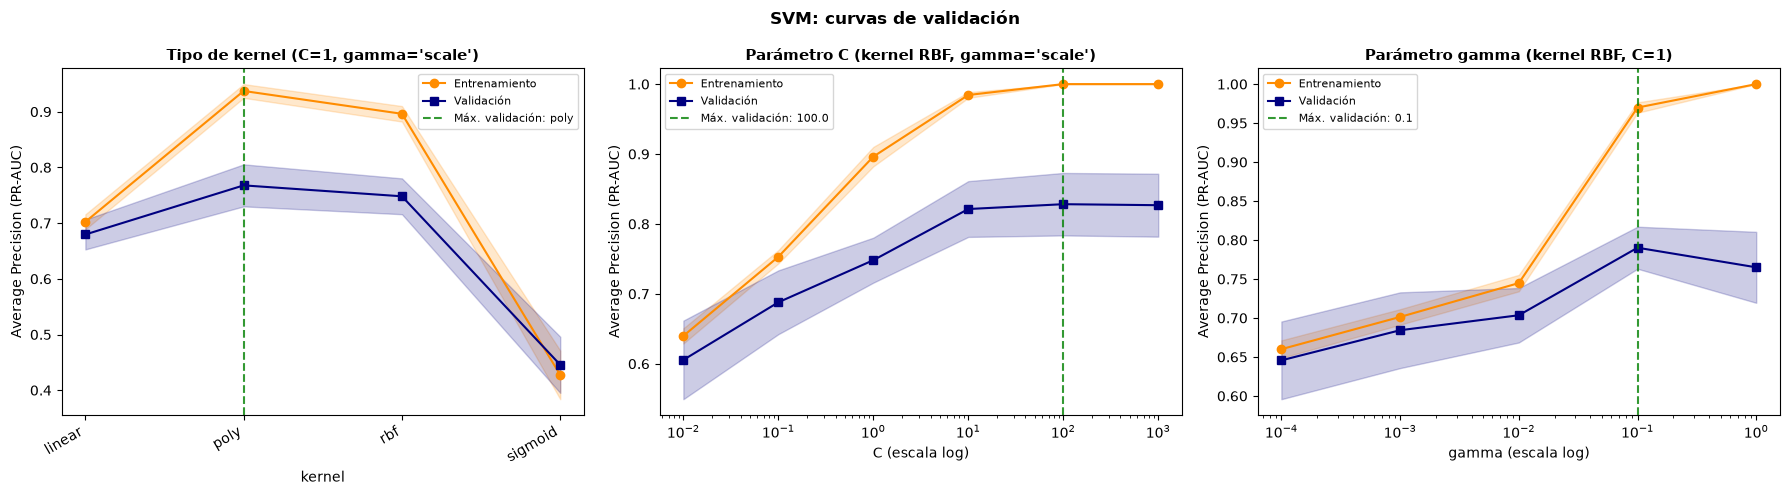

Optimizando modelo...

SVM (kernel RBF)
  Mejores hiperparametros: {'clf__C': 100, 'clf__gamma': 0.1}  PR-AUC validacion CV: 0.8508 +/- 0.0429 | entrenamiento: 1.0000 | brecha train-val: 0.1492


,params,mean_train_score,mean_test_score,std_test_score
14,"{'clf__C': 100, 'clf__gamma': 0.1}",1.0000,0.8508,0.0429
10,"{'clf__C': 10, 'clf__gamma': 0.1}",1.0000,0.8453,0.0415
6,"{'clf__C': 1, 'clf__gamma': 0.1}",0.9699,0.7901,0.0270
15,"{'clf__C': 100, 'clf__gamma': 1}",1.0000,0.7714,0.0420
11,"{'clf__C': 10, 'clf__gamma': 1}",1.0000,0.7714,0.0420


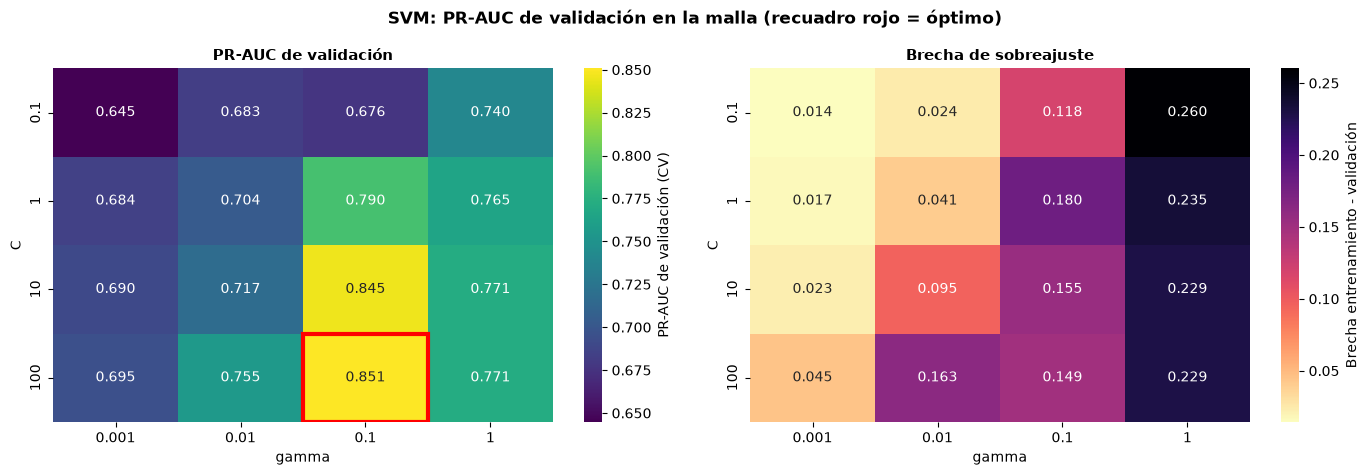

Tiempo total del Modelo 4: 0.3 min


In [7]:
from sklearn.svm import SVC

print("=== MODELO 4: MÁQUINA DE VECTORES DE SOPORTE (SVM) ===")

svm_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", SVC(
        kernel="rbf",
        class_weight="balanced",
        cache_size=500,
        random_state=SEED
    ))
])

inicio = time.time()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

rango_kernel = ["linear", "poly", "rbf", "sigmoid"]
curva_validacion(svm_base, "clf__kernel", rango_kernel, "Tipo de kernel (C=1, gamma='scale')",
                 "kernel", axes[0])

rango_C_svm = np.logspace(-2, 3, 6)
curva_validacion(svm_base, "clf__C", rango_C_svm, "Parámetro C (kernel RBF, gamma='scale')",
                 "C (escala log)", axes[1], log_x=True)

rango_gamma = np.logspace(-4, 0, 5)
curva_validacion(svm_base, "clf__gamma", rango_gamma, "Parámetro gamma (kernel RBF, C=1)",
                 "gamma (escala log)", axes[2], log_x=True)

fig.suptitle("SVM: curvas de validación", fontweight="bold")
plt.tight_layout()
guardar(fig, "13_svm_curvas_validacion")
plt.show()

print("Optimizando modelo...")
malla_svm = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": [0.001, 0.01, 0.1, 1],
}

grid_svm = GridSearchCV(
    svm_base, malla_svm, cv=cv_tuning, scoring=metrica, n_jobs=-1, return_train_score=True
)
grid_svm.fit(X_train, y_train)
resumen_grid("SVM (kernel RBF)", grid_svm)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
mapa_calor_grid(grid_svm, "clf__C", "clf__gamma", "PR-AUC de validación", axes[0], "C", "gamma")

r_svm = pd.DataFrame(grid_svm.cv_results_)
brecha = (r_svm["mean_train_score"] - r_svm["mean_test_score"]).values.reshape(
    len(malla_svm["clf__C"]), len(malla_svm["clf__gamma"]))
sns.heatmap(brecha, annot=True, fmt=".3f", cmap="magma_r", ax=axes[1],
            xticklabels=malla_svm["clf__gamma"], yticklabels=malla_svm["clf__C"],
            cbar_kws={"label": "Brecha entrenamiento - validación"})
axes[1].set_title("Brecha de sobreajuste", fontweight="bold", fontsize=11)
axes[1].set_xlabel("gamma")
axes[1].set_ylabel("C")
fig.suptitle("SVM: PR-AUC de validación en la malla (recuadro rojo = óptimo)", fontweight="bold")
plt.tight_layout()
guardar(fig, "13_svm_mapas_calor")
plt.show()

modelo_svm_final = grid_svm.best_estimator_

print(f"Tiempo total del Modelo 4: {(time.time() - inicio) / 60:.1f} min")

La mejor SVM usa kernel RBF con C = 100 y gamma = 0,1, y alcanza un PR-AUC de 0,851 en validación, con una brecha de 0,149. En la tabla se ve que con C alto y gamma = 0,1 rinde mejor, y que al subir gamma a 1 baja a 0,771 (con C = 100). Es el mejor de los cinco modelos en esta etapa, por eso pasa a la comparación final junto con el HGB.

# Modelo 5 — Red neuronal artificial (MLP)


=== MODELO 5: RED NEURONAL ARTIFICIAL (MLP) ===


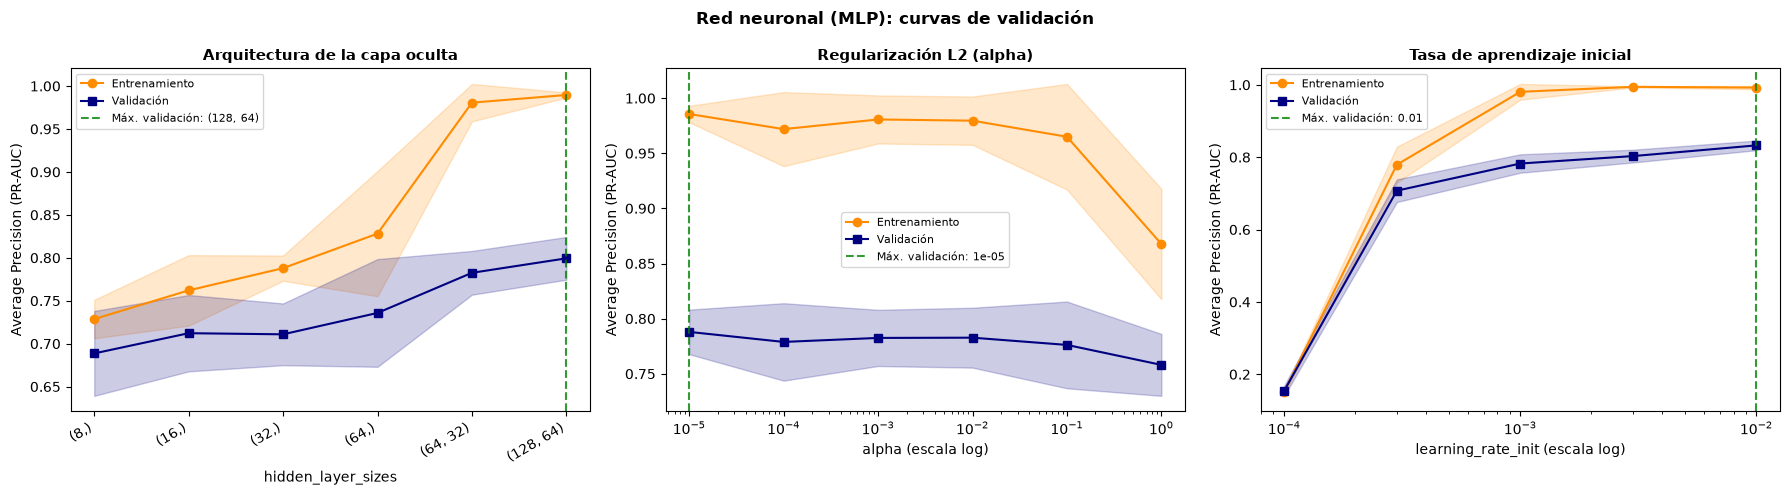

Optimizando modelo...

Red neuronal (MLP)
  Mejores hiperparametros: {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (128, 64)}  PR-AUC validacion CV: 0.8072 +/- 0.0287 | entrenamiento: 0.9904 | brecha train-val: 0.1832


,params,mean_train_score,mean_test_score,std_test_score
11,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes'...",0.9904,0.8072,0.0287
3,"{'clf__alpha': 0.0001, 'clf__hidden_layer_size...",0.9903,0.8013,0.0288
7,"{'clf__alpha': 0.001, 'clf__hidden_layer_sizes...",0.9896,0.7994,0.0249
15,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.9546,0.7901,0.0147
10,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes'...",0.9796,0.7827,0.0272


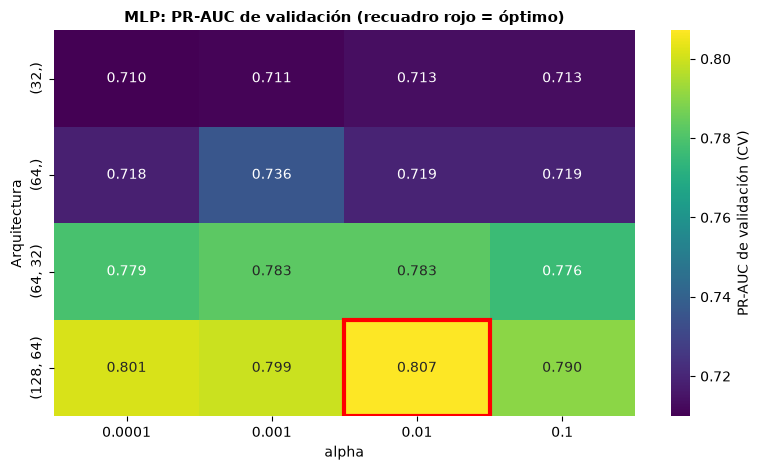

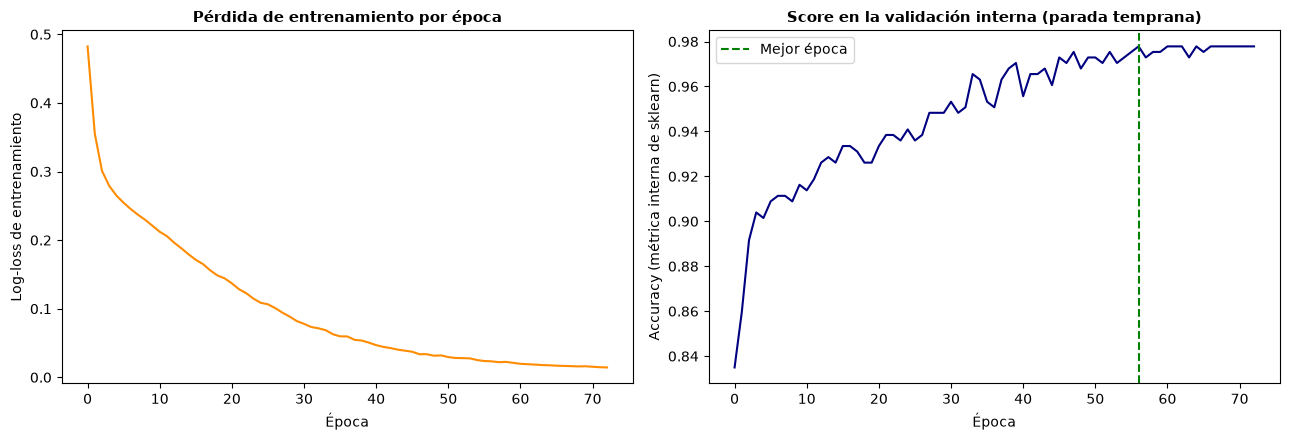

Épocas ejecutadas por la red final: 73 (max_iter = 500)
Tiempo total del Modelo 5: 0.5 min


In [8]:
from sklearn.neural_network import MLPClassifier

print("=== MODELO 5: RED NEURONAL ARTIFICIAL (MLP) ===")

mlp_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-3,
        learning_rate_init=1e-3,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        max_iter=500,
        random_state=SEED
    ))
])

inicio = time.time()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

arquitecturas = [(8,), (16,), (32,), (64,), (64, 32), (128, 64)]
curva_validacion(mlp_base, "clf__hidden_layer_sizes", arquitecturas, "Arquitectura de la capa oculta",
                 "hidden_layer_sizes", axes[0], etiquetas=[str(a) for a in arquitecturas])

rango_alpha = np.logspace(-5, 0, 6)
curva_validacion(mlp_base, "clf__alpha", rango_alpha, "Regularización L2 (alpha)",
                 "alpha (escala log)", axes[1], log_x=True)

rango_lr = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
curva_validacion(mlp_base, "clf__learning_rate_init", rango_lr, "Tasa de aprendizaje inicial",
                 "learning_rate_init (escala log)", axes[2], log_x=True)

fig.suptitle("Red neuronal (MLP): curvas de validación", fontweight="bold")
plt.tight_layout()
guardar(fig, "14_mlp_curvas_validacion")

plt.show()

print("Optimizando modelo...")
malla_mlp = {
    "clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
    "clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
}

grid_mlp = GridSearchCV(
    mlp_base, malla_mlp, cv=cv_tuning, scoring=metrica, n_jobs=-1, return_train_score=True
)
grid_mlp.fit(X_train, y_train)
resumen_grid("Red neuronal (MLP)", grid_mlp)

fig, ax = plt.subplots(figsize=(8, 4.8))
mapa_calor_grid(grid_mlp, "clf__hidden_layer_sizes", "clf__alpha",
                "MLP: PR-AUC de validación (recuadro rojo = óptimo)", ax, "Arquitectura", "alpha")
plt.tight_layout()
guardar(fig, "14_mlp_mapa_calor")
plt.show()

modelo_mlp_final = grid_mlp.best_estimator_

mlp_final = modelo_mlp_final.named_steps["clf"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(mlp_final.loss_curve_, color="darkorange")
axes[0].set_title("Pérdida de entrenamiento por época", fontweight="bold", fontsize=11)
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Log-loss de entrenamiento")

axes[1].plot(mlp_final.validation_scores_, color="navy")
axes[1].axvline(int(np.argmax(mlp_final.validation_scores_)), ls="--", color="green", label="Mejor época")
axes[1].set_title("Score en la validación interna (parada temprana)", fontweight="bold", fontsize=11)
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy (métrica interna de sklearn)")
axes[1].legend()
plt.tight_layout()
guardar(fig, "14_mlp_convergencia")

plt.show()

print(f"Épocas ejecutadas por la red final: {mlp_final.n_iter_} (max_iter = {mlp_final.max_iter})")
print(f"Tiempo total del Modelo 5: {(time.time() - inicio) / 60:.1f} min")

La red neuronal quedó con alpha = 0,01 y dos capas ocultas de 128 y 64 neuronas, con un PR-AUC de 0,807 en validación y una brecha de 0,183. La red final se detuvo en la época 73 de las 500 permitidas. Aprende bien, pero no supera a la SVM ni al Random Forest, y su ajuste (0,5 min) tomó más tiempo que el de la SVM (0,3 min).

In [9]:
guardar_estado("3_trainig",
    cv_tuning=cv_tuning,
    metrica=metrica,
    grid_lr=grid_lr,
    modelo_lr_final=modelo_lr_final,
    grid_knn=grid_knn,
    modelo_knn_final=modelo_knn_final,
    grid_rf=grid_rf,
    modelo_rf_final=modelo_rf_final,
    grid_svm=grid_svm,
    modelo_svm_final=modelo_svm_final,
    grid_mlp=grid_mlp,
    modelo_mlp_final=modelo_mlp_final,
)


WindowsPath('C:/Users/ASUS/Desktop/V8-final/data/processed/estado_3_trainig.joblib')

## Cierre de la etapa de entrenamiento

Con la validación cruzada de ajuste, el orden quedó así: SVM (0,851), Random Forest (0,835), MLP (0,807), KNN (0,764) y regresión logística (0,690). Por ahora vemos como candidatos fuertes a la SVM y al Random Forest, y dejamos la regresión logística como referencia. El HGB entra en 4_evaluation, donde hacemos la comparación definitiva con la CV repetida 5×5 y la evaluación en test.